# ARMA Model Applied to Walmart Weekly Sales
Based on `Project references/Time Series Codes/Scripts/5_AUTOREGRESSIVE_MOVING_AVERAGE_(ARMA)_MODEL.ipynb`,
which demonstrates ARMA simulation and ACF/PACF diagnostics on a **simulated**
series. Here we apply the same tools -- plotting, ACF/PACF, and ARMA fitting --
to a **real** dataset: `Walmart.csv` (45 stores, weekly sales, Feb 2010 - Oct 2012,
143 clean weeks per store, no gaps).

For each store we:
1. Plot the `Weekly_Sales` series.
2. Plot its ACF & PACF (same calls as the reference notebook).
3. Check stationarity (ADF test) and difference if needed.
4. Grid-search an ARMA(p,q) model by AIC (p, q in 0..3) and fit it with
   `statsmodels`.
5. Save every store's best order, AIC, and fitted coefficients to one table.

One store (Store 1) is walked through in full detail first; then the same
steps run for all 45 stores in a loop.

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

from pathlib import Path

plt.rcParams["figure.figsize"] = [10, 7.5]
%matplotlib inline

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "Walmart.csv").exists() else Path.cwd().parent
WALMART_CSV = PROJECT_ROOT / "Walmart.csv"
OUT_DIR = PROJECT_ROOT / "outputs" / "tables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Load the data
One row per store-week. `Date` is day-month-year; sales are already weekly, so
no resampling is needed.

In [2]:
df = pd.read_csv(WALMART_CSV)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

print(f"{df['Store'].nunique()} stores, {len(df)} rows total")
df.head()

45 stores, 6435 rows total


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


## Walkthrough on one store (Store 1)
Same three diagnostic steps as the reference ARMA notebook, just on a real
series instead of a simulated one.

**1. Plot the series**

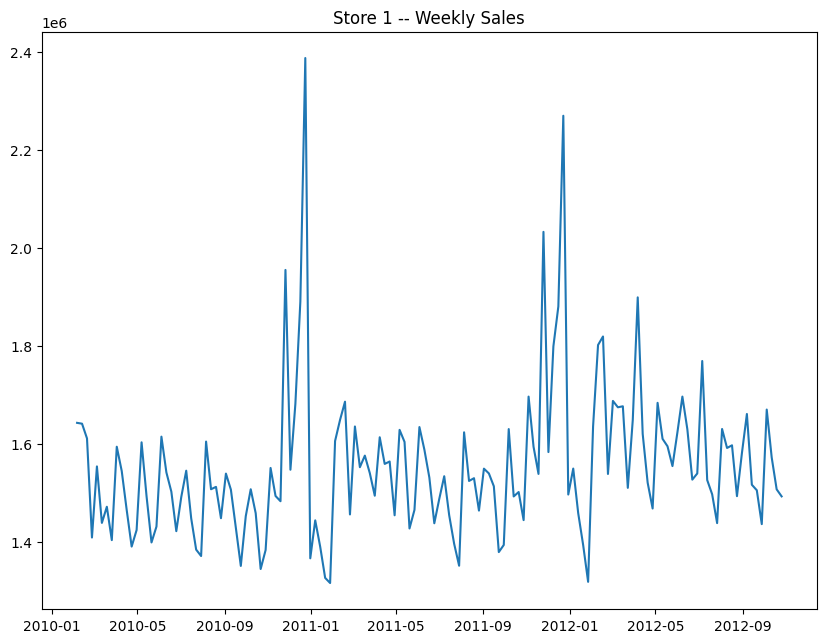

In [3]:
store1 = df[df["Store"] == 1].set_index("Date")["Weekly_Sales"]

plt.plot(store1)
plt.title("Store 1 -- Weekly Sales")
plt.show()

**2. Plot the ACF & PACF**
(identical calls to the reference notebook's `plot_pacf(...)` / `plot_acf(...)`)

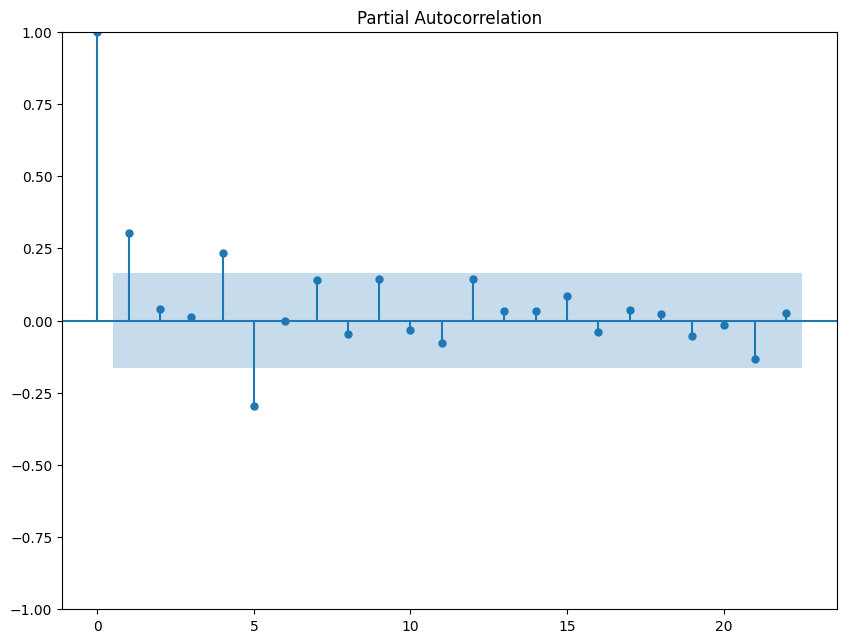

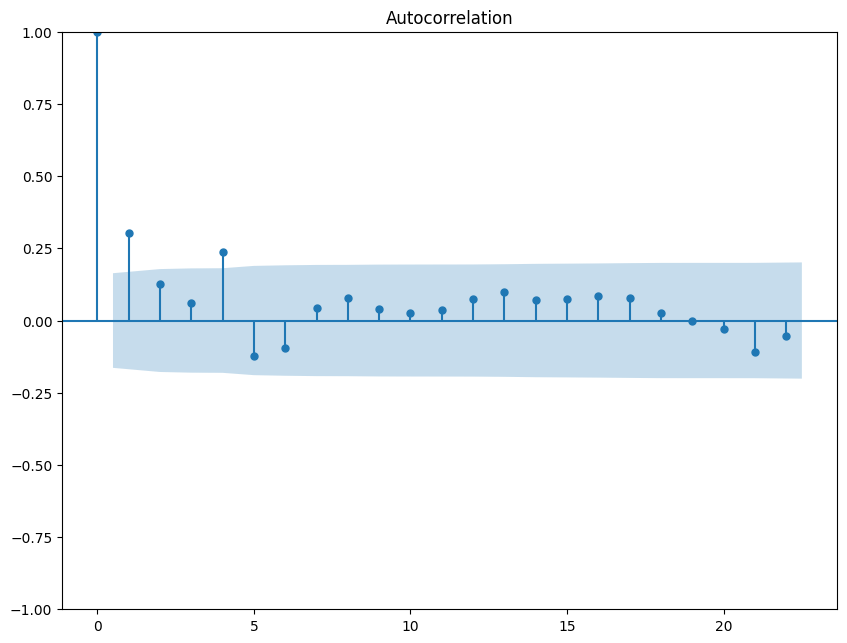

In [4]:
plot_pacf(store1);
plot_acf(store1);

**3. Check stationarity (ADF test), then difference if needed**
ARMA assumes a stationary series. The reference notebook skips this because its
series is simulated (already stationary by construction); real sales data
needs the check.

In [5]:
def adf_pvalue(series):
    return adfuller(series.dropna())[1]

p_level = adf_pvalue(store1)
print(f"ADF p-value (level): {p_level:.4f}")

if p_level < 0.05:
    d = 0
    series_to_model = store1
    print("Stationary at level -> d = 0")
else:
    d = 1
    series_to_model = store1.diff().dropna()
    p_diff = adf_pvalue(series_to_model)
    print(f"Non-stationary at level -> differencing. ADF p-value (diff): {p_diff:.4f} -> d = 1")

ADF p-value (level): 0.0000
Stationary at level -> d = 0


**4. Grid-search ARMA(p,q) by AIC, then fit the best model**

In [6]:
def best_arma_order(series, d, p_range=range(4), q_range=range(4)):
    best_aic, best_order, best_res = np.inf, None, None
    for p in p_range:
        for q in q_range:
            try:
                res = ARIMA(series, order=(p, d, q)).fit()
            except Exception:
                continue
            if res.aic < best_aic:
                best_aic, best_order, best_res = res.aic, (p, d, q), res
    return best_order, best_res

order1, res1 = best_arma_order(store1, d)
print(f"Best order for Store 1: {order1}  AIC={res1.aic:,.1f}")
print(res1.summary())

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


Best order for Store 1: (2, 0, 2)  AIC=3,802.2
                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  143
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -1895.106
Date:                Mon, 19 Oct 2026   AIC                           3802.213
Time:                        12:28:21   BIC                           3819.990
Sample:                    02-05-2010   HQIC                          3809.437
                         - 10-26-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.555e+06   1.98e+04     78.529      0.000    1.52e+06    1.59e+06
ar.L1         -0.9335      0.127     -7.323      0.000      -1.183      -0.684
ar.L2

**5. Residual diagnostics**
If the model captured the autocorrelation, the residual ACF/PACF should look
like white noise (no significant spikes).

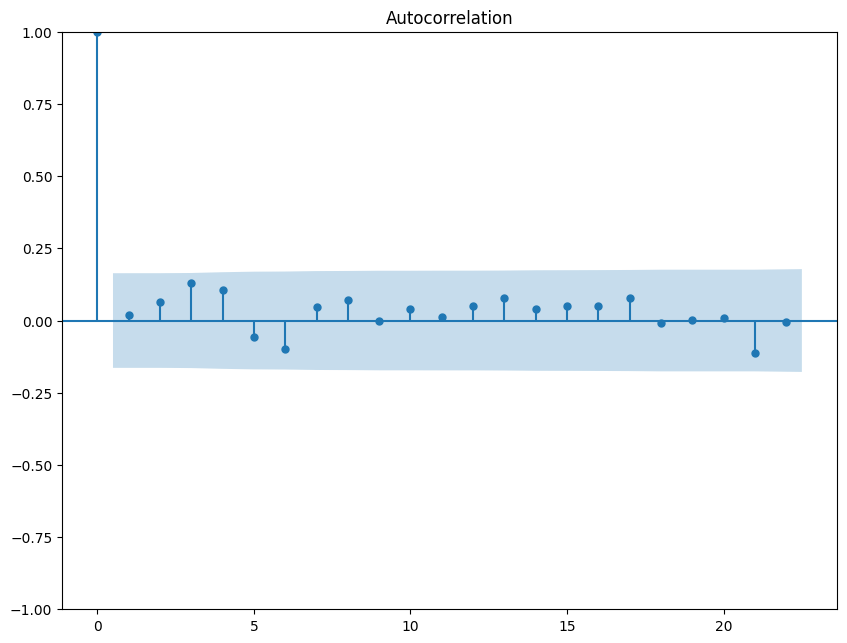

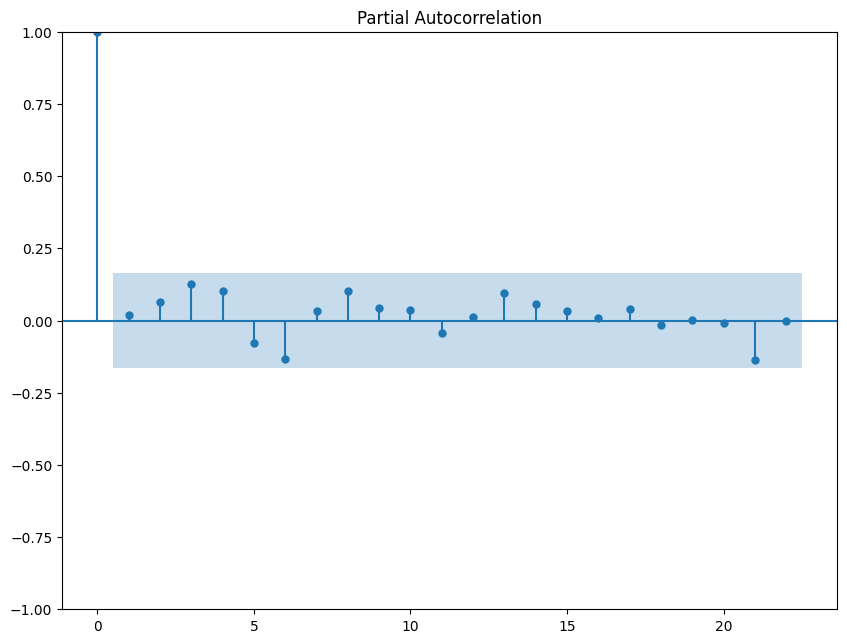

In [7]:
plot_acf(res1.resid);
plot_pacf(res1.resid);

**6. Formal diagnostic check: Ljung-Box test**
The residual ACF/PACF plots above look like white noise, but "looks like" isn't
a decision rule. The Ljung-Box test formalizes Step 3 of the flowchart: if the
p-values are all above 0.05, we fail to reject the null of no residual
autocorrelation -> residuals are white noise -> proceed to Step 4
(Forecasting). If any p-value is below 0.05, the flowchart says to go back to
Step 1 and try a different order.

In [8]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(res1.resid, lags=[10, 20], return_df=True)
print(lb)

jb_stat, jb_p = res1.test_normality("jarquebera")[0][:2]
print(f"\nJarque-Bera normality test: stat={jb_stat:.2f}, p-value={jb_p:.4f}")

residuals_white_noise = (lb["lb_pvalue"] > 0.05).all()
if residuals_white_noise:
    print("\nAll Ljung-Box p-values > 0.05 -> residuals are white noise -> proceed to Step 4 (Forecasting)")
else:
    print("\nAt least one Ljung-Box p-value <= 0.05 -> residuals are NOT white noise -> flowchart says return to Step 1")

      lb_stat  lb_pvalue
10   8.265061   0.602964
20  11.796846   0.922891

Jarque-Bera normality test: stat=111.23, p-value=0.0000

All Ljung-Box p-values > 0.05 -> residuals are white noise -> proceed to Step 4 (Forecasting)


## Step 4: Forecasting (Store 1)
Diagnostics passed, so we move to the last box in the flowchart. To evaluate
the forecast honestly, we hold out the **last 12 weeks** of Store 1 as a test
set, refit ARMA(2,0,2) -- the order identified in Step 1 -- on the remaining
131 weeks only, and forecast 12 steps ahead.

In [9]:
n_test = 12
train, test = store1.iloc[:-n_test], store1.iloc[-n_test:]

forecast_model = ARIMA(train, order=order1).fit()
fc = forecast_model.get_forecast(steps=n_test)
fc_mean = fc.predicted_mean
fc_ci = fc.conf_int(alpha=0.05)

print(f"Train: {len(train)} weeks ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} weeks ({test.index.min().date()} to {test.index.max().date()})")
print(f"\nRefit order {order1} on train only -> AIC={forecast_model.aic:,.1f}")

Train: 131 weeks (2010-02-05 to 2012-08-03)
Test:  12 weeks (2012-08-10 to 2012-10-26)

Refit order (2, 0, 2) on train only -> AIC=3,491.8


C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


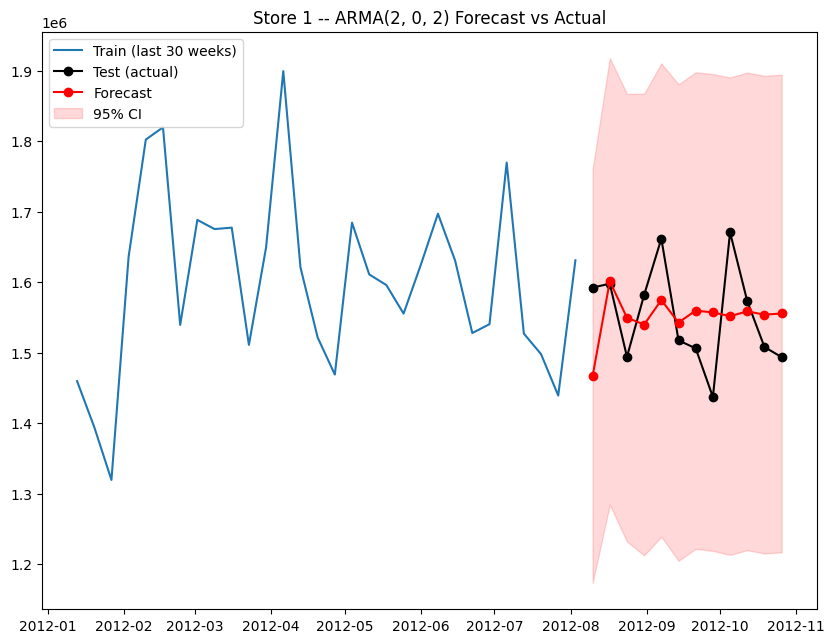

In [10]:
plt.plot(train.iloc[-30:], label="Train (last 30 weeks)")
plt.plot(test, label="Test (actual)", color="black", marker="o")
plt.plot(fc_mean, label="Forecast", color="red", marker="o")
plt.fill_between(fc_ci.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1],
                  color="red", alpha=0.15, label="95% CI")
plt.title(f"Store 1 -- ARMA{order1} Forecast vs Actual")
plt.legend()
plt.show()

In [11]:
rmse = np.sqrt(np.mean((test.values - fc_mean.values) ** 2))
mae = np.mean(np.abs(test.values - fc_mean.values))
mape = np.mean(np.abs((test.values - fc_mean.values) / test.values)) * 100

print(f"RMSE: {rmse:,.2f}")
print(f"MAE:  {mae:,.2f}")
print(f"MAPE: {mape:.2f}%")

RMSE: 74,445.53
MAE:  62,850.11
MAPE: 4.05%


**Store 1 walkthrough complete.** Identification (ADF -> d=0, AIC grid search ->
ARMA(2,0,2)) -> Parameter estimation (fitted via `ARIMA(...).fit()`) ->
Diagnostic checking (Ljung-Box on residuals passed) -> Forecasting (12-week
holdout forecast with 95% CI, evaluated by RMSE/MAE/MAPE). The same four steps
are applied to all 45 stores (identification + estimation only, by AIC) in the
loop below.

## Apply the same steps to all 45 stores
Loop store by store: ADF test -> difference if needed -> grid-search ARMA(p,q)
by AIC -> record the best order, AIC, and fitted coefficients.

In [12]:
results = []
for store_id, g in df.groupby("Store"):
    series = g.set_index("Date")["Weekly_Sales"]

    p_level = adf_pvalue(series)
    if p_level < 0.05:
        d = 0
        series_to_model = series
    else:
        d = 1
        series_to_model = series.diff().dropna()

    order, res = best_arma_order(series_to_model, d)
    if res is None:
        print(f"  store {store_id}: all ARMA fits failed, skipping")
        continue

    results.append({
        "store": int(store_id),
        "adf_pvalue_level": p_level,
        "differenced": d == 1,
        "order_pdq": order,
        "aic": res.aic,
        "bic": res.bic,
        "params": res.params.to_dict(),
    })
    print(f"  store {store_id}: best order={order} AIC={res.aic:,.1f}{' [differenced]' if d else ''}")

print(f"\nFitted {len(results)} / {df['Store'].nunique()} stores")

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


...

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-

  store 45: best order=(3, 0, 3) AIC=3,747.8

Fitted 45 / 45 stores


C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ritarshi Roy\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


## Results table
One row per store: its chosen ARMA order, whether it needed differencing, and
the resulting AIC/BIC.

In [13]:
results_df = pd.DataFrame([
    {
        "store": r["store"],
        "adf_pvalue_level": r["adf_pvalue_level"],
        "differenced": r["differenced"],
        "p": r["order_pdq"][0],
        "d": r["order_pdq"][1],
        "q": r["order_pdq"][2],
        "aic": r["aic"],
        "bic": r["bic"],
    }
    for r in results
]).sort_values("store").reset_index(drop=True)

out_path = OUT_DIR / "walmart_arma_results.csv"
results_df.to_csv(out_path, index=False)
print(f"Saved {out_path}")
results_df

Saved C:\Users\Ritarshi Roy\Downloads\ATSA Project\outputs\tables\walmart_arma_results.csv


,store,adf_pvalue_level,differenced,p,d,q,aic,bic
0,1,1.387779e-05,False,2,0,2,3802.212936,3819.990004
1,2,3.990207e-03,False,3,0,3,3913.009284,3936.712041
2,3,3.840926e-02,False,3,0,2,3426.665528,3447.405440
3,4,4.779866e-02,False,3,0,3,3936.755485,3960.458242
4,5,4.251706e-04,False,2,0,3,3395.698523,3416.438435
5,6,2.159486e-06,False,3,0,3,3877.940783,3901.643540
6,7,2.170072e-04,False,3,0,3,3645.042915,3668.745672
7,8,1.002746e-06,False,2,0,2,3693.928928,3711.705996
8,9,2.134309e-05,False,3,0,3,3563.274679,3586.977436
9,10,8.763068e-06,False,3,0,3,3968.788152,3992.490909


## Summary
- Count of stores that needed differencing (`d = 1`) vs. not.
- Most common ARMA order chosen across stores.

In [14]:
print("Differenced (d=1):", results_df['differenced'].sum(), "/", len(results_df))
print()
print("Most common (p, d, q) orders:")
print(results_df.groupby(["p", "d", "q"]).size().sort_values(ascending=False).head(10))

Differenced (d=1): 7 / 45

Most common (p, d, q) orders:
p  d  q
3  0  3    19
2  0  2    10
3  1  3     6
1  0  2     5
3  0  2     3
0  1  3     1
2  0  3     1
dtype: int64
